# 04. Признаки и утечка через PageValues

**Цель.** Решить, на каких признаках учить модель:
1. разобраться, можно ли честно использовать `PageValues`;
2. проверить, помогают ли новые поведенческие признаки и простые преобразования.

Каждое решение проверяю на кросс-валидации и записываю в журнал экспериментов (`reports/experiments_log.md`).

**Что уже известно из 01-03.**
- Данные уже разделены на train/test (ноутбук 01). Здесь работаю только с train.
- Распределения счётчиков и длительностей сильно скошены, связь времени с покупкой нелинейная (02).
- `PageValues` подозрительно сильный признак: при значении больше нуля конверсия 56.5%, при нуле 3.7% (02).

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

from src.config import CATEGORICAL_RAW, NUMERIC_RAW, RANDOM_STATE, TARGET
from src.data import load_train, split_xy
from src.evaluation import compare_pipelines, get_cv
from src.experiments import log_experiment
from src.features import ENGINEERED, TECH_CODES, add_behavior_features, make_model_pipeline
from src.plots import BLUE, GRAY, INK_2, ORANGE, save_fig, setup_style

setup_style()
pd.set_option("display.precision", 4)

train = load_train()
X, y = split_xy(train)
print(f"train: {X.shape[0]} сессий, {X.shape[1]} исходных признаков, конверсия {y.mean():.1%}")

train: 9864 сессий, 17 исходных признаков, конверсия 15.5%


## Как я сравниваю варианты

**Модели для экспериментов.** Беру две модели:
- **логистическую регрессию**, простую линейную модель, которая чувствительна к тому, в каком виде поданы признаки;
- **случайный лес (Random Forest)** с настройками по умолчанию, то есть набор из 300 деревьев решений, который сам находит нелинейности.

Гиперпараметры подбираю в 05. Здесь задача в том, чтобы сравнить наборы признаков при прочих равных.

**Метрика.** Главная метрика **PR-AUC** (площадь под кривой precision-recall). Простыми словами: насколько хорошо модель ставит настоящих покупателей в начало списка, отсортированного по "вероятности покупки". Случайное угадывание даёт PR-AUC, равный доле покупок (около 0.155), идеальная модель даёт 1. Дополнительно смотрю **ROC-AUC**: вероятность, что случайный покупатель получит от модели оценку выше, чем случайный не купивший (0.5 как у монетки, 1 у идеальной модели). Подробнее о метриках расскажу в 05.

**Кросс-валидация.** *Кросс-валидация* позволяет оценить модель без теста: train делится на 5 частей, модель учится на четырёх и проверяется на пятой, и так 5 раз. Я повторяю это 3 раза с разным разбиением, получается 15 оценок. Все варианты признаков проверяются на **одних и тех же** 15 разбиениях, поэтому их можно сравнивать попарно на каждом разбиении.

**Правило принятия решений (фиксирую заранее):**
- изменение **оставляю**, если средний PR-AUC вырос хотя бы на 0.005 и рост есть минимум в 10 из 15 разбиений;
- если изменение ни на что не влияет (разница меньше 0.005, направление неустойчивое), выбираю **более простой** вариант;
- иначе **отказываюсь**.

Порог 0.005 взял, потому что разброс PR-AUC между разбиениями около 0.015. Более мелкие различия я не считаю надёжными.

In [2]:
cv = get_cv(n_repeats=3)

logreg = LogisticRegression(max_iter=5000)
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=1,
                                random_state=RANDOM_STATE)

numeric_with_pv = NUMERIC_RAW
numeric_no_pv = [c for c in NUMERIC_RAW if c != "PageValues"]

def lr_pipe(numeric, categorical, log=True):
    return make_model_pipeline(logreg, numeric, categorical, log=log, scale=True)

def rf_pipe(numeric, categorical):
    # Деревьям не важен масштаб и монотонные преобразования, поэтому без log и скейлинга
    return make_model_pipeline(forest, numeric, categorical, log=False, scale=False)

def fmt_delta(table, name, base_metric="pr_auc"):
    row = table.loc[name]
    return (f"PR-AUC {row['PR-AUC']:.3f} (Δ {row[f'Δ {base_metric} к базе']:+.4f}, "
            f"лучше в {row['фолдов лучше базы']} разбиений)")

## 1. PageValues: что это и можно ли его использовать

### Как считается признак

По описанию на UCI, `PageValues` означает среднюю "ценность" страниц, которые посетитель открыл перед покупкой. Это стандартная метрика Google Analytics (Universal Analytics). Для каждой страницы сайта:

> ценность страницы = (выручка покупок + ценность достигнутых целей) / число уникальных просмотров страницы,

причём в выручку идут только те покупки, **перед которыми** эту страницу смотрели. Считается по всем сессиям за период отчёта. Для сессии в датасете записано среднее этой величины по страницам, которые посетитель посмотрел.

Отсюда два вопроса:
1. **Попадает ли в признак выручка самой этой сессии?** Если посетитель купил, страницы, которые он смотрел до покупки, получают "кусочек" его выручки. Значит, у покупателя `PageValues` растёт *из-за его же покупки*. Это и есть *утечка целевой переменной*: признак частично содержит ответ.
2. **Используются ли будущие данные?** Ценность считается по всему периоду (году). Значение для мартовской сессии учитывает покупки, сделанные в ноябре.

### Проверка на данных

In [3]:
pv_positive = X["PageValues"] > 0
print(f"Доля покупателей с PageValues > 0: {pv_positive[y == 1].mean():.1%}")
print(f"Доля не купивших с PageValues > 0: {pv_positive[y == 0].mean():.1%}")
print(f"Покупателей с PageValues = 0: {(~pv_positive[y == 1]).sum()} из {(y == 1).sum()}")

# Насколько хорошо один-единственный признак ранжирует покупателей (без обучения)
print(f"\nPageValues сам по себе: ROC-AUC = {roc_auc_score(y, X['PageValues']):.3f}, "
      f"PR-AUC = {average_precision_score(y, X['PageValues']):.3f}")
for col in ["ProductRelated_Duration", "ProductRelated", "ExitRates"]:
    sign = -1 if col == "ExitRates" else 1  # у ExitRates связь обратная
    print(f"{col} сам по себе: ROC-AUC = {roc_auc_score(y, sign * X[col]):.3f}, "
          f"PR-AUC = {average_precision_score(y, sign * X[col]):.3f}")

Доля покупателей с PageValues > 0: 81.3%
Доля не купивших с PageValues > 0: 11.4%
Покупателей с PageValues = 0: 286 из 1526

PageValues сам по себе: ROC-AUC = 0.867, PR-AUC = 0.630
ProductRelated_Duration сам по себе: ROC-AUC = 0.675, PR-AUC = 0.245
ProductRelated сам по себе: ROC-AUC = 0.660, PR-AUC = 0.240
ExitRates сам по себе: ROC-AUC = 0.711, PR-AUC = 0.269


**Что увидел.** У 81.3% покупателей `PageValues > 0`, а у не купивших только у 11.4%. Один этот признак, без всякой модели, даёт ROC-AUC 0.867 и PR-AUC 0.630. Для сравнения: лучший из остальных признаков, показатель выхода, даёт ROC-AUC 0.711 и PR-AUC 0.269, а время на товарных страницах 0.675 и 0.245. При этом у 286 покупателей из 1526 (18.7%) `PageValues = 0`. Значит, утечка не "механическая" 1-в-1: если бы выручка сессии всегда попадала в признак, у каждого покупателя он был бы больше нуля.

Как именно авторы агрегировали метрику до сессии, восстановить нельзя. Но по определению признак строится из выручки, и вклад самой сессии в него, скорее всего, есть.

### Эксперимент: модели с PageValues и без него

In [4]:
pv_table = compare_pipelines({
    "ЛР без PageValues": lr_pipe(numeric_no_pv, CATEGORICAL_RAW),
    "ЛР с PageValues": lr_pipe(numeric_with_pv, CATEGORICAL_RAW),
    "Лес без PageValues": rf_pipe(numeric_no_pv, CATEGORICAL_RAW),
    "Лес с PageValues": rf_pipe(numeric_with_pv, CATEGORICAL_RAW),
}, X, y, cv, baseline="ЛР без PageValues")
pv_table

,ROC-AUC,PR-AUC,PR-AUC std,Δ pr_auc к базе,фолдов лучше базы
вариант,,,,,
ЛР без PageValues,0.7591,0.3360,0.0163,0.0000,0/15
ЛР с PageValues,0.9168,0.6898,0.0167,0.3537,15/15
Лес без PageValues,0.7849,0.3882,0.0216,0.0521,15/15
Лес с PageValues,0.9288,0.7488,0.0150,0.4128,15/15


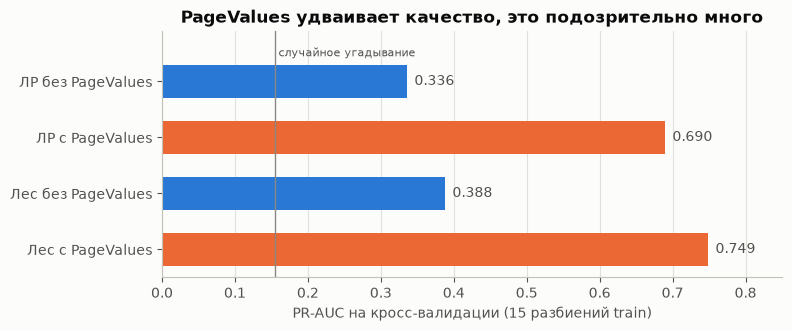

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = pv_table.index[::-1]
values = pv_table["PR-AUC"][::-1]
colors = [ORANGE if "с PageValues" in name else BLUE for name in labels]
ax.barh(labels, values, color=colors, height=0.6)
for i, v in enumerate(values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", color=INK_2)
ax.axvline(y.mean(), color=GRAY, linewidth=1)
ax.text(y.mean() + 0.005, len(labels) - 0.6, "случайное угадывание", color=INK_2, fontsize=8, va="bottom")
ax.set_ylim(-0.5, len(labels) - 0.1)
ax.set_xlim(0, 0.85)
ax.set_xlabel("PR-AUC на кросс-валидации (15 разбиений train)")
ax.set_title("PageValues удваивает качество, это подозрительно много")
ax.grid(axis="y", visible=False)
save_fig(fig, "04_pagevalues_effect")
plt.show()

**Что увидел.** С `PageValues` PR-AUC у логистической регрессии вырастает с 0.336 до 0.690, у леса с 0.388 до 0.749. ROC-AUC растёт с 0.76-0.78 до 0.92-0.93. Улучшение во всех 15 разбиениях. Ни одно другое изменение в этом ноутбуке не даёт даже десятой доли такого прироста.

### Решение

Для чего модель будет использоваться: **решить во время визита, показать ли посетителю промокод**, то есть до того, как он купил или ушёл.

В этот момент:
1. выручки текущей сессии ещё нет. А в `PageValues` из датасета у покупателей она, скорее всего, уже учтена;
2. ценность страниц по будущим месяцам ещё неизвестна.

Честный аналог в реальной жизни возможен: "историческая" ценность страниц, посчитанная только по прошлым покупкам *других* людей. Магазин с GA мог бы её считать. Но восстановить её из этого датасета нельзя.

Поэтому:
- **основная модель строится без `PageValues`**. Её качество (PR-AUC около 0.34-0.39) я считаю честной оценкой;
- модель с `PageValues` оставлю в 05 как **оптимистичную верхнюю границу**: "сколько можно было бы выжать, если бы честный исторический аналог работал так же хорошо". Скорее всего, он работал бы хуже.

Без этого разбора легко получить ROC-AUC около 0.93 и решить, что модель отличная. На деле значительная часть этого качества получена за счёт подсказки из будущего.

In [6]:
log_experiment(
    "1", "04", "PageValues может содержать выручку самой сессии (утечка)",
    "логистическая регрессия: добавил PageValues к исходным признакам",
    fmt_delta(pv_table, "ЛР с PageValues"),
    "отказываюсь в основной модели: признак недоступен в момент выдачи промокода; оставляю как верхнюю границу",
)
log_experiment(
    "2", "04", "То же для случайного леса",
    "случайный лес: добавил PageValues",
    f"PR-AUC {pv_table.loc['Лес без PageValues', 'PR-AUC']:.3f} → {pv_table.loc['Лес с PageValues', 'PR-AUC']:.3f}",
    "отказываюсь в основной модели (та же причина)",
)

### Другие признаки из GA: показатели отказов и выхода

`BounceRates` и `ExitRates` тоже считаются GA по страницам за весь период. Но они строятся не из выручки, а из того, уходят ли люди с этих страниц, и текущая сессия даёт лишь один из многих просмотров. Поэтому утечка тут слабее, а исторический аналог в реальности есть всегда. Проверяю, насколько модель на них опирается.

In [7]:
rates_table = compare_pipelines({
    "ЛР без PageValues": lr_pipe(numeric_no_pv, CATEGORICAL_RAW),
    "ЛР без PageValues и без Bounce/Exit": lr_pipe(
        [c for c in numeric_no_pv if c not in ("BounceRates", "ExitRates")], CATEGORICAL_RAW),
}, X, y, cv, baseline="ЛР без PageValues")
rates_table

,ROC-AUC,PR-AUC,PR-AUC std,Δ pr_auc к базе,фолдов лучше базы
вариант,,,,,
ЛР без PageValues,0.7591,0.3360,0.0163,0.0000,0/15
ЛР без PageValues и без Bounce/Exit,0.7408,0.3186,0.0196,-0.0174,0/15


In [8]:
log_experiment(
    "3", "04", "Показатели отказов и выхода тоже метрики GA за весь период: сколько модель на них опирается",
    "логистическая регрессия без BounceRates и ExitRates",
    fmt_delta(rates_table, "ЛР без PageValues и без Bounce/Exit"),
    "оставляю их: вклад заметный, а исторический аналог в реальности доступен",
)

**Что увидел.** Без показателей отказов и выхода PR-AUC падает с 0.336 до 0.319, ухудшение в 15 из 15 разбиений.

**Что это значит.** Модель на них опирается, но умеренно. Я их оставляю, но записываю в ограничения: в реальной системе их нужно считать только по прошлым данным, и качество может немного отличаться.

## 2. Логарифм для логистической регрессии

**Идея.** В 02 распределения счётчиков и длительностей оказались сильно скошены, а связь времени с покупкой нелинейной: первые минуты важнее последующих. Логистическая регрессия "линейна" по признакам: каждая лишняя минута для неё одинаково важна. Логарифм `log(1 + x)` сжимает большие значения: разница между 1 и 10 минутами становится такой же, как между 10 и 100. Ожидаю, что это поможет регрессии. Для леса проверять смысла нет: деревьям всё равно, как растянута шкала.

In [9]:
log_table = compare_pipelines({
    "ЛР с log": lr_pipe(numeric_no_pv, CATEGORICAL_RAW, log=True),
    "ЛР без log": lr_pipe(numeric_no_pv, CATEGORICAL_RAW, log=False),
}, X, y, cv, baseline="ЛР без log")
log_table

,ROC-AUC,PR-AUC,PR-AUC std,Δ pr_auc к базе,фолдов лучше базы
вариант,,,,,
ЛР с log,0.7591,0.3360,0.0163,0.012,15/15
ЛР без log,0.7517,0.3241,0.0171,0.000,0/15


In [10]:
log_experiment(
    "4", "04", "Распределения скошены, связь с временем нелинейная → логарифм поможет регрессии",
    "log(1+x) для числовых признаков в логистической регрессии",
    fmt_delta(log_table, "ЛР с log"),
    "оставляю",
)

**Что увидел.** С логарифмом PR-AUC 0.336 против 0.324 без него (+0.012), ROC-AUC 0.759 против 0.752. Рост во всех 15 разбиениях.

**Что это значит.** Гипотеза из 02 подтвердилась: регрессии логарифмированные признаки подходят лучше. Логарифм оставляю во всех дальнейших пайплайнах регрессии.

## 3. Технические коды: ОС, браузер, регион

**Идея.** Коды операционной системы, браузера и региона не расшифрованы. Регион по результатам 03 не связан с покупкой (p = 0.68). Если убрать эти признаки, модель станет проще (меньше колонок после one-hot кодирования), а качество, ожидаю, не изменится.

*One-hot кодирование* нужно, чтобы подать категорию модели: для каждого значения заводится отдельная колонка "да/нет". Например, "месяц = ноябрь: 1, месяц = май: 0, ...".

In [11]:
categorical_short = [c for c in CATEGORICAL_RAW if c not in TECH_CODES]
print("Оставшиеся категориальные:", categorical_short)

tech_table = compare_pipelines({
    "ЛР все категории": lr_pipe(numeric_no_pv, CATEGORICAL_RAW),
    "ЛР без ОС/браузера/региона": lr_pipe(numeric_no_pv, categorical_short),
}, X, y, cv, baseline="ЛР все категории")
tech_table_rf = compare_pipelines({
    "Лес все категории": rf_pipe(numeric_no_pv, CATEGORICAL_RAW),
    "Лес без ОС/браузера/региона": rf_pipe(numeric_no_pv, categorical_short),
}, X, y, cv, baseline="Лес все категории")
pd.concat([tech_table, tech_table_rf])

Оставшиеся категориальные: ['Month', 'VisitorType', 'Weekend', 'TrafficType']


,ROC-AUC,PR-AUC,PR-AUC std,Δ pr_auc к базе,фолдов лучше базы
вариант,,,,,
ЛР все категории,0.7591,0.3360,0.0163,0.0000,0/15
ЛР без ОС/браузера/региона,0.7579,0.3400,0.0129,0.0039,8/15
Лес все категории,0.7849,0.3882,0.0216,0.0000,0/15
Лес без ОС/браузера/региона,0.7847,0.3880,0.0165,-0.0002,8/15


In [12]:
log_experiment(
    "5", "04", "Нерасшифрованные коды ОС/браузера/региона не помогают (регион незначим в 03)",
    "убрал OperatingSystems, Browser, Region",
    f"ЛР: {fmt_delta(tech_table, 'ЛР без ОС/браузера/региона')}; "
    f"лес: {fmt_delta(tech_table_rf, 'Лес без ОС/браузера/региона')}",
    "оставляю (качество то же, модель проще)",
)

**Что увидел.** Для регрессии: PR-AUC 0.340 против 0.336 (+0.004, лучше в 8 из 15 разбиений). Для леса: 0.388 и 0.388 (разница -0.0002).

**Что это значит.** Разница в пределах шума. По правилу выбираю более простой вариант: **без ОС, браузера и региона**. Модели проще, а интерпретировать их легче: остаются только признаки, у которых есть понятный смысл.

## 4. Новые поведенческие признаки

Для каждого признака записал гипотезу, зачем он может быть нужен:

| Признак | Как считается | Гипотеза |
|---|---|---|
| `total_pages` | все страницы за визит | общая "вовлечённость" визита важнее разбивки по типам страниц |
| `total_duration` | всё время за визит, сек | то же по времени |
| `product_share` | товарные / все страницы | кто смотрит в основном товары, тот выбирает покупку, а кто читает "о магазине", тот пока изучает |
| `avg_product_time` | время на товарных / число товарных страниц | отличает вдумчивое изучение карточки от быстрого пролистывания каталога |
| `avg_page_time` | всё время / все страницы | то же для всего визита |
| `visited_admin` | были ли служебные страницы (0/1) | служебные страницы (вход, аккаунт) выдают "своего" клиента, который готов покупать; у купивших медиана 2 таких страницы, у ушедших 0 |

Все признаки считаются по одной строке, поэтому их можно добавить внутри Pipeline без риска утечки (класс `BehaviorFeatures` в `src/features.py`).

In [13]:
# Как новые признаки выглядят у купивших и не купивших (медианы)
engineered_view = add_behavior_features(X)[ENGINEERED].assign(купил=y.values)
engineered_view.groupby("купил").median().T.rename(columns={0: "не купили", 1: "купили"}).round(3)

купил,не купили,купили
total_pages,18.000,32.500
total_duration,587.375,1254.417
product_share,0.974,0.929
avg_product_time,27.421,35.840
avg_page_time,28.291,36.380
visited_admin,0.000,1.000


**Что увидел.** По медианам новые признаки различаются у групп: у купивших больше страниц (32.5 против 18) и дольше визит (1254 против 587 секунд). Доля товарных страниц почти одинаковая (0.93 против 0.97, у купивших даже чуть ниже, потому что они чаще открывают служебные страницы). Среднее время на товарную страницу у купивших выше: 36 против 27 секунд.

Различия есть. Но вопрос в другом: дают ли эти признаки модели что-то сверх исходных?

In [14]:
eng_table = compare_pipelines({
    "ЛР база": lr_pipe(numeric_no_pv, categorical_short),
    "ЛР + все новые": lr_pipe(numeric_no_pv + ENGINEERED, categorical_short),
    **{f"ЛР + {f}": lr_pipe(numeric_no_pv + [f], categorical_short) for f in ENGINEERED},
}, X, y, cv, baseline="ЛР база")
eng_table

,ROC-AUC,PR-AUC,PR-AUC std,Δ pr_auc к базе,фолдов лучше базы
вариант,,,,,
ЛР база,0.7579,0.3400,0.0129,0.0000e+00,0/15
ЛР + все новые,0.7587,0.3399,0.0104,-8.5785e-05,8/15
ЛР + total_pages,0.7585,0.3409,0.0131,9.2182e-04,15/15
ЛР + total_duration,0.7576,0.3388,0.0127,-1.1084e-03,1/15
ЛР + product_share,0.7582,0.3407,0.0131,7.9682e-04,13/15
ЛР + avg_product_time,0.7578,0.3397,0.0128,-2.1770e-04,7/15
ЛР + avg_page_time,0.7578,0.3382,0.0133,-1.7029e-03,0/15
ЛР + visited_admin,0.7580,0.3404,0.0105,4.7844e-04,10/15


In [15]:
eng_table_rf = compare_pipelines({
    "Лес база": rf_pipe(numeric_no_pv, categorical_short),
    "Лес + все новые": rf_pipe(numeric_no_pv + ENGINEERED, categorical_short),
}, X, y, cv, baseline="Лес база")
eng_table_rf

,ROC-AUC,PR-AUC,PR-AUC std,Δ pr_auc к базе,фолдов лучше базы
вариант,,,,,
Лес база,0.7847,0.388,0.0165,0.000,0/15
Лес + все новые,0.7825,0.383,0.0172,-0.005,4/15


In [16]:
log_experiment(
    "6", "04", "Поведенческие признаки (6 шт.) дают модели новую информацию",
    "добавил все 6 новых признаков",
    f"ЛР: {fmt_delta(eng_table, 'ЛР + все новые')}; лес: {fmt_delta(eng_table_rf, 'Лес + все новые')}",
    "отказываюсь: прироста нет",
)
best_single = eng_table.drop(index=["ЛР база", "ЛР + все новые"])["Δ pr_auc к базе"].idxmax()
log_experiment(
    "7", "04", "Может, помогает какой-то один из новых признаков",
    "добавлял по одному признаку к логистической регрессии",
    f"лучший: {best_single.replace('ЛР + ', '')}, {fmt_delta(eng_table, best_single)}",
    "отказываюсь: прирост меньше порога 0.005",
)

**Что увидел.**
- Все 6 признаков вместе: у регрессии PR-AUC 0.340 → 0.340 (-0.0001), у леса 0.388 → 0.383 (-0.005).
- По одному: лучший `total_pages`, +0.0009. Рост стабильный (15 из 15 разбиений), но крошечный, в 5 раз меньше моего порога. `avg_page_time` даже стабильно ухудшает регрессию (-0.0017, 0 из 15).

**Что это значит.** Гипотезы не подтвердились: новые признаки не добавляют информации. Сначала я удивился, но объяснение простое.
- Для регрессии с логарифмом отношение двух признаков ничего нового не даёт: `log(время / страницы) = log(время) - log(страницы)`, а такую разность регрессия умеет строить сама, подобрав коэффициенты.
- Лес сам находит комбинации признаков через последовательные разбиения.
- "Средние" признаки ещё и зашумлены нулевыми длительностями (время последней страницы теряется, см. 01). Это, вероятно, объясняет, почему `avg_page_time` слегка вредит.

В модель новые признаки не беру. Но они пригодятся в 06, чтобы *описывать* сегменты понятным языком ("сколько секунд на карточку товара").

## Итоговый набор признаков

In [17]:
final_numeric = numeric_no_pv
final_categorical = categorical_short
print(f"Числовые ({len(final_numeric)}):", final_numeric)
print(f"Категориальные ({len(final_categorical)}):", final_categorical)

final_table = compare_pipelines({
    "ЛР итог": lr_pipe(final_numeric, final_categorical),
    "Лес итог": rf_pipe(final_numeric, final_categorical),
}, X, y, cv, baseline="ЛР итог")
final_table

Числовые (9): ['Administrative', 'Informational', 'ProductRelated', 'Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']
Категориальные (4): ['Month', 'VisitorType', 'Weekend', 'TrafficType']


,ROC-AUC,PR-AUC,PR-AUC std,Δ pr_auc к базе,фолдов лучше базы
вариант,,,,,
ЛР итог,0.7579,0.340,0.0129,0.000,0/15
Лес итог,0.7847,0.388,0.0165,0.048,15/15


Итоговые списки признаков я записал в `src/features.py` (`MAIN_NUMERIC`, `MAIN_CATEGORICAL`), чтобы следующие ноутбуки использовали ровно этот набор. Проверка, что списки совпадают:

In [18]:
from src.features import MAIN_CATEGORICAL, MAIN_NUMERIC
assert MAIN_NUMERIC == final_numeric and MAIN_CATEGORICAL == final_categorical
print("Списки в src/features.py совпадают с выбранными здесь.")

Списки в src/features.py совпадают с выбранными здесь.


## Итоги

- **`PageValues` почти наверняка содержит утечку**: один этот признак даёт ROC-AUC 0.867, а с ним PR-AUC модели вырастает с 0.336 до 0.690 (регрессия) и с 0.388 до 0.749 (лес). В момент выдачи промокода он недоступен, поэтому основная модель строится **без него**.
- **Логарифм** улучшает логистическую регрессию: +0.012 PR-AUC, во всех 15 разбиениях.
- **ОС, браузер и регион** можно убрать без потери качества (разница в пределах ±0.004).
- **Шесть новых поведенческих признаков не помогли** (лучший +0.0009). Регрессия с логарифмом и лес извлекают ту же информацию из исходных признаков.
- Итог: 9 числовых признаков + 4 категориальных. Честная оценка до подбора гиперпараметров: PR-AUC 0.340 у регрессии и 0.388 у леса.

## Что не получилось или удивило

- Я рассчитывал, что признаки вроде "среднего времени на товарную страницу" дадут прирост. Не дали. Это хороший урок: признак, который отличается у групп, не обязательно добавляет модели *новую* информацию.
- Масштаб утечки. Без разбора `PageValues` проект выглядел бы гораздо успешнее, чем он есть.

## Новые идеи

- Сделать честный аналог `PageValues` при наличии данных: ценность страниц по прошлым периодам, без текущей сессии.
- Модель на "неполных" сессиях (первые N страниц) была бы ближе к реальному сценарию промокода. Для этого нужны данные о порядке просмотров.

## Следующие шаги

- **В ноутбуке 05** построю бейзлайн, логистическую регрессию и случайный лес с подбором гиперпараметров на итоговом наборе, разберусь с дисбалансом и порогом и сделаю финальную проверку на тесте.
- **При большем времени:** признаки взаимодействия для регрессии (например, "новый посетитель × месяц"), которые лес находит сам.